# SMS Spam Detection with a Pretrained Transformer

**Course:** Hacking AI · Master's program, 3rd semester
**Team:** Juan José Aguado · Juan David Cruz · Juan Diego Ramírez

This notebook walks through the full data science process behind **SpamLens**, the Django web app in `../app`.
We follow a CRISP-DM style flow:

| # | Stage | Question it answers |
|---|-------|---------------------|
| 1 | Business understanding | What are we trying to decide, and how do we measure it? |
| 2 | Data understanding (EDA) | What does SMS spam look like compared with legitimate messages? |
| 3 | Privacy-aware statistics | Can we publish the EDA without exposing any single message? |
| 4 | Data preparation | How do we split and tokenize without leaking information? |
| 5 | Modeling | How does the pretrained `Goodmotion/spam-mail-classifier` behave on SMS, and how do we adapt it? |
| 6 | Evaluation | Which model and threshold do we ship, and where does it still fail? |
| 7 | Deployment | What does the web app load, and what does it promise its users? |

**Data:** [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (UCI), 5,574 English SMS messages labeled `ham` or `spam`.
**Pretrained model:** [`Goodmotion/spam-mail-classifier`](https://huggingface.co/Goodmotion/spam-mail-classifier), a `Multilingual-MiniLM-L12-H384` fine-tuned to tell spam from legitimate **email subjects**.
**Recommended reading:** Dwork & Roth, *The Algorithmic Foundations of Differential Privacy* (2014), used in section 3.

## 1. Business understanding

A spam filter makes two kinds of mistakes, and they do not cost the same:

* **False positive** (a real message flagged as spam): the user may miss a bank code, a family message or an appointment. This is the expensive error.
* **False negative** (spam that gets through): annoying and sometimes dangerous (phishing), but the user still sees it and can judge it.

So accuracy alone is a poor target: a model that says "ham" to everything already scores about 87% on this data. We track:

* **Precision on spam**: of the messages we flag, how many really are spam (protects against false positives).
* **Recall on spam**: of the spam that exists, how much we catch.
* **F1 on spam** as the single summary number, plus **ROC-AUC** and **average precision** to compare models independently of the threshold.

Success criterion for the app: spam F1 above 0.90 on a held-out test set that no model or threshold decision has seen.

In [1]:
import csv
import io
import json
import os
import random
import re
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification, AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())

ROOT = Path('..').resolve()
DATA_ZIP = ROOT / 'data' / 'sms+spam+collection.zip'
PRETRAINED = 'Goodmotion/spam-mail-classifier'
LOCAL_PRETRAINED = ROOT / 'model'            # optional local copy of the Hugging Face snapshot
FINETUNED_DIR = ROOT / 'model' / 'finetuned'  # where the adapted model is saved for the app
MODEL_CARD = ROOT / 'app' / 'classifier' / 'model_card.json'

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'ham': '#2f6f6a', 'spam': '#d1495b'}
print('torch', torch.__version__, '| threads', torch.get_num_threads())

torch 2.15.0+cpu | threads 12


## 2. Data understanding

The zip ships two files: the tab-separated corpus and the original readme. We read the corpus straight from the zip so the raw file never has to be extracted.
`quoting=csv.QUOTE_NONE` matters: many messages contain unbalanced quote characters, and the default parser would silently merge rows.

In [2]:
with zipfile.ZipFile(DATA_ZIP) as zf:
    print(zf.namelist())
    raw = zf.read('SMSSpamCollection').decode('utf-8', errors='replace')

df = pd.read_csv(io.StringIO(raw), sep='\t', header=None, names=['label', 'text'], quoting=csv.QUOTE_NONE)
print(df.shape)
df.head(8)

['SMSSpamCollection', 'readme']
(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...


In [3]:
quality = pd.Series({
    'rows': len(df),
    'null labels': df['label'].isna().sum(),
    'null texts': df['text'].isna().sum(),
    'empty texts': (df['text'].str.strip() == '').sum(),
    'unique labels': df['label'].nunique(),
    'exact duplicate texts': df.duplicated('text').sum(),
    'texts duplicated with conflicting labels': df.groupby('text')['label'].nunique().gt(1).sum(),
})
quality.to_frame('value')

,value
rows,5574
null labels,0
null texts,0
empty texts,0
unique labels,2
exact duplicate texts,403
texts duplicated with conflicting labels,0


In [4]:
dup = df[df.duplicated('text', keep=False)]
print('Duplicate rows by class:')
print(dup.drop_duplicates('text')['label'].value_counts())
dup['text'].value_counts().head(5)

Duplicate rows by class:
label
ham     194
spam     87
Name: count, dtype: int64


text
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!                                     4
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Name: count, dtype: int64

**Takeaways on quality.** No nulls and no label conflicts, but roughly 400 exact duplicates (mostly ham chatter such as "Sorry, I'll call later" and repeated spam campaigns).
Duplicates do not hurt EDA much, but they are dangerous for evaluation: if the same text lands in train and test, the test score measures memory, not generalization. We drop them in section 4 **before** splitting.

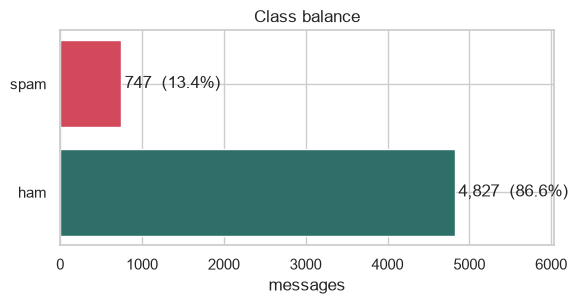

In [5]:
counts = df['label'].value_counts()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
for i, v in enumerate(counts.values):
    ax.text(v + 40, i, f'{v:,}  ({v / len(df):.1%})', va='center')
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title('Class balance')
ax.set_xlabel('messages')
plt.tight_layout()
plt.show()

The dataset is **imbalanced (about 13% spam)**. This confirms the choice of metrics from section 1, and means we will stratify every split so each subset keeps the same ratio.

### 2.1 Shape of a message

We engineer a few interpretable features. They are not fed to the transformer; they exist to understand what separates the classes and to explain the model's behaviour later.

In [6]:
URL_RE = re.compile(r'(?:https?://|www\.|\.(?:com|co\.uk|net|org)\b)', re.I)
PHONE_RE = re.compile(r'\b\d{5,}\b')
MONEY_RE = re.compile(r'[£$€]|\b\d+\s?(?:p|pence|gbp)\b', re.I)

def featurize(s: pd.Series) -> pd.DataFrame:
    letters = s.str.count(r'[A-Za-z]').clip(lower=1)
    return pd.DataFrame({
        'chars': s.str.len(),
        'words': s.str.split().str.len(),
        'digits_ratio': s.str.count(r'\d') / s.str.len(),
        'upper_ratio': s.str.count(r'[A-Z]') / letters,
        'exclamations': s.str.count('!'),
        'has_url': s.str.contains(URL_RE),
        'has_long_number': s.str.contains(PHONE_RE),
        'has_money': s.str.contains(MONEY_RE),
    })

feats = pd.concat([df[['label']], featurize(df['text'])], axis=1)
summary = feats.groupby('label').mean(numeric_only=True).T
summary['spam / ham'] = summary['spam'] / summary['ham'].replace(0, np.nan)
summary.round(3)

label,ham,spam,spam / ham
chars,71.472,138.676,1.940
words,14.304,23.912,1.672
digits_ratio,0.004,0.117,27.489
upper_ratio,0.079,0.167,2.127
exclamations,0.177,0.730,4.133
has_url,0.003,0.185,63.695
has_long_number,0.001,0.756,1216.981
has_money,0.004,0.518,131.618


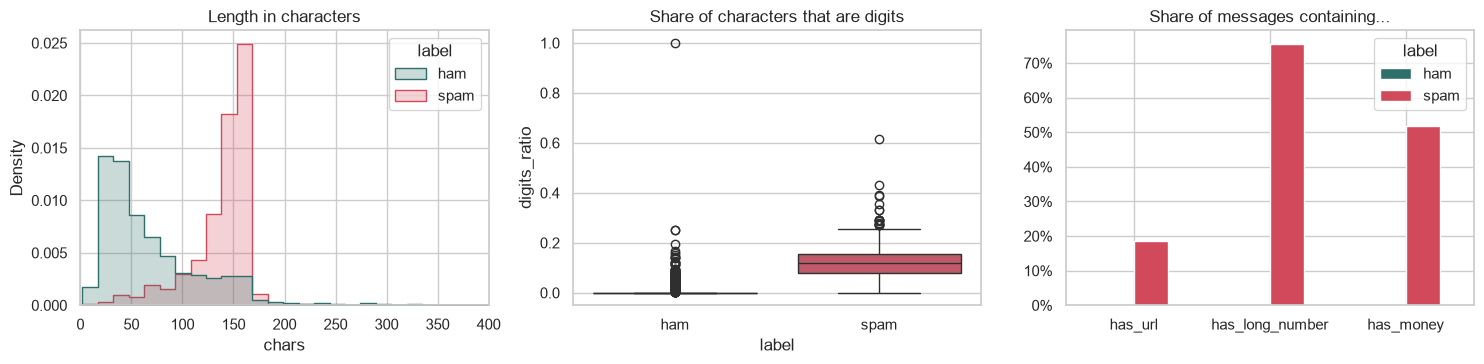

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(feats, x='chars', hue='label', bins=60, stat='density', common_norm=False,
             palette=PALETTE, element='step', ax=axes[0])
axes[0].set_xlim(0, 400)
axes[0].set_title('Length in characters')
sns.boxplot(feats, x='label', y='digits_ratio', hue='label', palette=PALETTE, ax=axes[1], legend=False)
axes[1].set_title('Share of characters that are digits')
flags = feats.groupby('label')[['has_url', 'has_long_number', 'has_money']].mean().T
flags.plot.bar(color=[PALETTE['ham'], PALETTE['spam']], ax=axes[2], rot=0)
axes[2].set_title('Share of messages containing...')
axes[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout()
plt.show()

**What the shape tells us**

* Spam is long and tight: it clusters around 140 to 160 characters, the old single-SMS limit, because senders pay per message and fill it. Ham is short and spread out.
* Spam is full of digits: short codes, phone numbers, prices. Most spam carries a 5+ digit number, while almost no ham does.
* Money symbols and URLs are near-exclusive to spam.

So a large part of the signal is **lexical and numeric**, which is why we will keep digits and casing when preparing text for the transformer.

### 2.2 Vocabulary

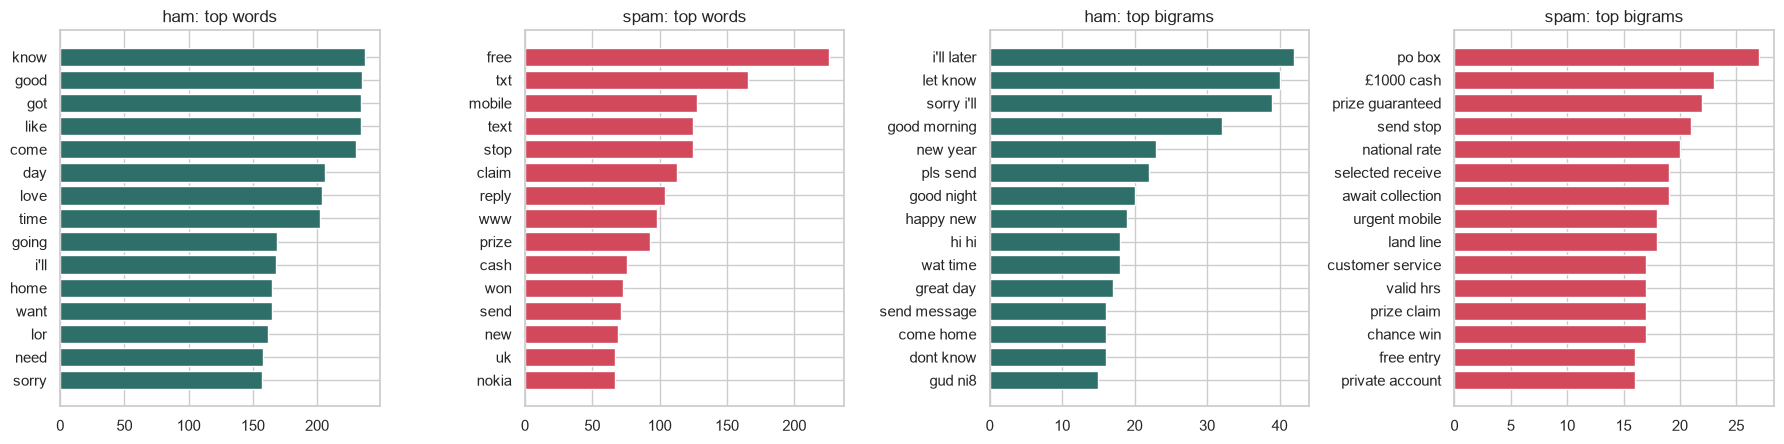

In [8]:
TOKEN_RE = re.compile(r"[a-z£$€][a-z0-9'£$€]+")
STOP = set(ENGLISH_STOP_WORDS) | {'u', 'ur', 'im', "i'm", 'lt', 'gt', 'just', 'ok', 'don', "don't", "it's", 'ü', 'll'}

def top_tokens(texts, n=15, ngram=1):
    c = Counter()
    for t in texts:
        toks = [w for w in TOKEN_RE.findall(t.lower()) if w not in STOP]
        c.update(zip(*[toks[i:] for i in range(ngram)]) if ngram > 1 else toks)
    return pd.Series({(' '.join(k) if isinstance(k, tuple) else k): v for k, v in c.most_common(n)})

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (lab, ng) in zip(axes, [('ham', 1), ('spam', 1), ('ham', 2), ('spam', 2)]):
    s = top_tokens(df.loc[df.label == lab, 'text'], ngram=ng)[::-1]
    ax.barh(s.index, s.values, color=PALETTE[lab])
    ax.set_title(f'{lab}: top {"words" if ng == 1 else "bigrams"}')
plt.tight_layout()
plt.show()

Spam vocabulary is a sales pitch: *free, call, txt, claim, prize, won, mobile, reply, urgent*, and bigrams like *prize guaranteed* or *call landline*. Ham is conversational SMS slang: *come, got, know, like, good, love, time*, with heavy abbreviation (*u, ur, lor, da*).

That slang is a warning sign for the pretrained model: it was trained on **email subjects**, a register with few abbreviations and almost no phone numbers. We will measure that gap in section 5.

## 3. Privacy-aware statistics (Dwork & Roth, ch. 2 and 3)

The numbers above are aggregates over real people's text messages. Aggregates feel safe, but they are not: if we published "how many messages mention *call*" before and after one person's messages were added, the difference reveals something about that person. This is the *differencing attack* that motivates differential privacy.

**Definition (ε-differential privacy).** A randomized mechanism $\mathcal{M}$ is ε-DP if for every pair of datasets $D, D'$ that differ in one record and every set of outputs $S$:

$$\Pr[\mathcal{M}(D) \in S] \le e^{\varepsilon} \, \Pr[\mathcal{M}(D') \in S]$$

**Laplace mechanism (Theorem 3.6).** For a query $f$ with ℓ1-sensitivity $\Delta f$, releasing $f(D) + \text{Lap}(\Delta f / \varepsilon)$ is ε-DP.

A histogram (here, the class counts or the length histogram) has sensitivity $\Delta f = 1$: adding or removing one message changes exactly one bin by one. So we can publish a whole histogram with noise of scale $1/\varepsilon$ per bin. Below we release the EDA histograms privately and look at the price we pay in accuracy.

In [9]:
rng = np.random.default_rng(SEED)

def laplace_histogram(counts: np.ndarray, epsilon: float, sensitivity: float = 1.0) -> np.ndarray:
    # Laplace mechanism on a histogram, then clamp at 0 (post-processing keeps the guarantee).
    noisy = counts + rng.laplace(0.0, sensitivity / epsilon, size=counts.shape)
    return np.clip(noisy, 0, None)

true_counts = df['label'].value_counts().reindex(['ham', 'spam']).to_numpy()
rows = []
for eps in [0.01, 0.1, 0.5, 1.0, 5.0]:
    noisy = laplace_histogram(true_counts.astype(float), eps)
    rows.append({'epsilon': eps, 'ham (noisy)': round(noisy[0]), 'spam (noisy)': round(noisy[1]),
                 'spam share (noisy)': f'{noisy[1] / noisy.sum():.2%}'})
print('True counts:', dict(zip(['ham', 'spam'], true_counts)), f'| spam share {true_counts[1] / true_counts.sum():.2%}')
pd.DataFrame(rows)

True counts: {'ham': np.int64(4827), 'spam': np.int64(747)} | spam share 13.40%


,epsilon,ham (noisy),spam (noisy),spam share (noisy)
0,0.01,4906,734,13.01%
1,0.10,4840,752,13.45%
2,0.50,4824,753,13.50%
3,1.00,4828,748,13.41%
4,5.00,4827,747,13.40%


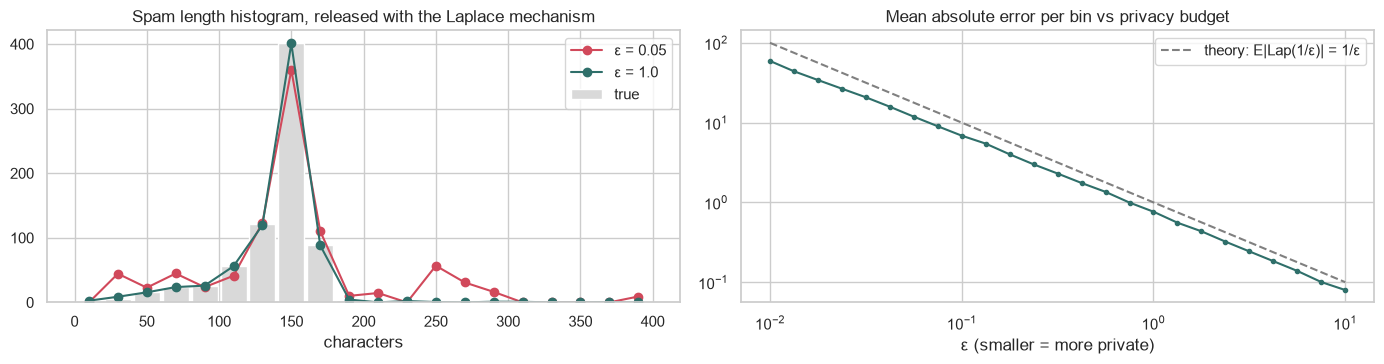

In [10]:
bins = np.arange(0, 420, 20)
spam_len = feats.loc[feats.label == 'spam', 'chars'].clip(upper=bins[-1] - 1)
true_hist, _ = np.histogram(spam_len, bins=bins)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
centers = (bins[:-1] + bins[1:]) / 2
axes[0].bar(centers, true_hist, width=18, color='#d9d9d9', label='true')
for eps, color in [(0.05, '#d1495b'), (1.0, '#2f6f6a')]:
    axes[0].plot(centers, laplace_histogram(true_hist.astype(float), eps), marker='o', color=color, label=f'ε = {eps}')
axes[0].set_title('Spam length histogram, released with the Laplace mechanism')
axes[0].set_xlabel('characters')
axes[0].legend()

eps_grid = np.logspace(-2, 1, 25)
err = [np.mean([np.abs(laplace_histogram(true_hist.astype(float), e) - true_hist).mean() for _ in range(200)])
       for e in eps_grid]
axes[1].loglog(eps_grid, err, color='#2f6f6a', marker='.')
axes[1].loglog(eps_grid, 1 / eps_grid, ls='--', color='grey', label='theory: E|Lap(1/ε)| = 1/ε')
axes[1].set_title('Mean absolute error per bin vs privacy budget')
axes[1].set_xlabel('ε (smaller = more private)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the result.** With ε = 1 the per-bin error is about one message, so the shape of every EDA chart survives intact while the release is formally private. With ε = 0.05 the error grows to about 20 messages per bin and the small bins start to dissolve. Because our counts are in the hundreds or thousands, aggregate EDA is cheap to privatize; the cost only bites for rare categories.

Two lessons carry into the app:

1. **The model is trained without DP.** Fine-tuned models can memorize rare training strings (Dwork & Roth §8.1 on reconstruction attacks). The SMS corpus is public research data, so this is acceptable here, but training on private user messages would call for DP-SGD.
2. **Data minimization.** The app classifies a message in memory and never stores, logs or shares it. The safest data to protect is data you never kept.

## 4. Data preparation

**Cleaning.** Transformers need very little: we keep case, digits and punctuation because section 2 showed they carry signal. We only strip surrounding whitespace and decode the HTML entities (`&lt;`, `&gt;`, `&amp;`) that the corpus inherited from its web sources.

**Deduplication before splitting**, so no text appears in more than one subset.

**Split.** Stratified 70 / 15 / 15:
* *train* fits the models,
* *validation* chooses epochs and the decision threshold,
* *test* is touched once, at the end.

In [11]:
import html

clean = df.assign(text=df['text'].map(lambda t: html.unescape(t).strip()))
clean = clean.drop_duplicates('text').reset_index(drop=True)
clean['y'] = (clean['label'] == 'spam').astype(int)
print(f'{len(df):,} rows -> {len(clean):,} unique messages ({len(df) - len(clean)} duplicates removed)')

train_df, temp_df = train_test_split(clean, test_size=0.30, stratify=clean['y'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['y'], random_state=SEED)
splits = {'train': train_df, 'validation': val_df, 'test': test_df}
pd.DataFrame({k: {'messages': len(v), 'spam': int(v['y'].sum()), 'spam share': f"{v['y'].mean():.2%}"}
              for k, v in splits.items()}).T

5,574 rows -> 5,160 unique messages (414 duplicates removed)


,messages,spam,spam share
train,3612,449,12.43%
validation,774,97,12.53%
test,774,96,12.40%


### 4.1 Tokenization

The pretrained model uses an XLM-R SentencePiece tokenizer (250k multilingual vocabulary). We check how many tokens our messages need so we can pick `max_length` without truncating real content.

In [12]:
MODEL_SOURCE = str(LOCAL_PRETRAINED) if (LOCAL_PRETRAINED / 'config.json').exists() else PRETRAINED
tokenizer = AutoTokenizer.from_pretrained(MODEL_SOURCE)
n_tokens = clean['text'].map(lambda t: len(tokenizer(t)['input_ids']))
print(n_tokens.describe(percentiles=[.5, .9, .95, .99]).round(1))
print('Example:', tokenizer.tokenize(clean.loc[clean.y == 1, 'text'].iloc[0])[:24])

MAX_LEN = 128
print(f'max_length = {MAX_LEN} keeps {(n_tokens <= MAX_LEN).mean():.2%} of messages whole')

count    5160.0
mean       25.1
std        17.3
min         3.0
50%        19.0
90%        49.0
95%        55.0
99%        73.8
max       225.0
Name: text, dtype: float64
Example: ['▁Free', '▁entry', '▁in', '▁2', '▁a', '▁w', 'k', 'ly', '▁comp', '▁to', '▁win', '▁FA', '▁Cup', '▁final', '▁t', 'kt', 's', '▁21', 'st', '▁May', '▁2005.', '▁Text', '▁FA', '▁to']
max_length = 128 keeps 99.83% of messages whole


## 5. Modeling

We compare three models on exactly the same splits:

1. **Baseline**: TF-IDF (word 1-2 grams + character 3-5 grams) with logistic regression. Cheap, transparent, and the bar any transformer has to beat.
2. **Pretrained, zero-shot**: `Goodmotion/spam-mail-classifier` used as published.
3. **Pretrained, fine-tuned**: the same network, adapted to SMS with our training split (transfer learning).

### 5.1 Baseline

In [13]:
from scipy.sparse import hstack

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
X_train = hstack([word_vec.fit_transform(train_df.text), char_vec.fit_transform(train_df.text)]).tocsr()

def tfidf(texts):
    return hstack([word_vec.transform(texts), char_vec.transform(texts)]).tocsr()

baseline = LogisticRegression(C=10, class_weight='balanced', max_iter=2000)
baseline.fit(X_train, train_df.y)
p_val_base = baseline.predict_proba(tfidf(val_df.text))[:, 1]
p_test_base = baseline.predict_proba(tfidf(test_df.text))[:, 1]
print(f'validation | F1 {f1_score(val_df.y, p_val_base > 0.5):.3f} | AUC {roc_auc_score(val_df.y, p_val_base):.3f}')

validation | F1 0.927 | AUC 0.998


### 5.2 The pretrained model, zero-shot

According to its `training.py`, label `1` is `SPAM` and label `0` is `NOSPAM`. We score every split in batches with dynamic padding.

In [14]:
@torch.inference_mode()
def predict_proba(model, texts, batch_size=64):
    model.eval()
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tokenizer(list(texts[i:i + batch_size]), padding=True, truncation=True,
                          max_length=MAX_LEN, return_tensors='pt')
        out.append(torch.softmax(model(**batch).logits, dim=-1)[:, 1])
    return torch.cat(out).numpy()

pretrained = AutoModelForSequenceClassification.from_pretrained(MODEL_SOURCE)
n_params = sum(p.numel() for p in pretrained.parameters())
print(f'{pretrained.config.architectures[0]} | {n_params / 1e6:.0f}M parameters')

t0 = time.time()
p_val_zero = predict_proba(pretrained, val_df.text.tolist())
p_test_zero = predict_proba(pretrained, test_df.text.tolist())
print(f'scored {len(val_df) + len(test_df):,} messages in {time.time() - t0:.0f}s')
print(classification_report(val_df.y, p_val_zero > 0.5, target_names=['ham', 'spam'], digits=3))
print(f'ROC-AUC {roc_auc_score(val_df.y, p_val_zero):.3f}')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification | 118M parameters


scored 1,548 messages in 12s
              precision    recall  f1-score   support

         ham      0.929     0.388     0.548       677
        spam      0.157     0.794     0.262        97

    accuracy                          0.439       774
   macro avg      0.543     0.591     0.405       774
weighted avg      0.833     0.439     0.512       774

ROC-AUC 0.640


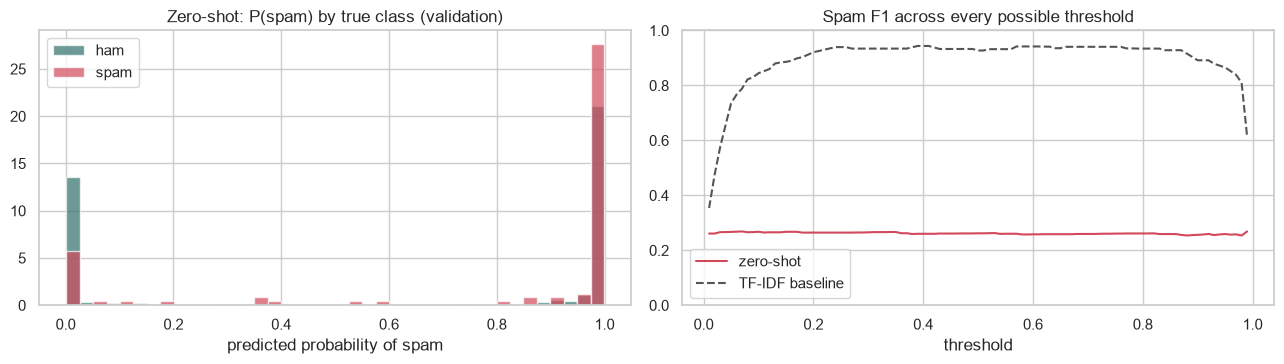

Ham flagged as spam at 0.5: 61% of legitimate messages
The legitimate messages it is most sure are spam:
  0.999  That sucks. I'll go over so u can do my hair. You'll do it free right?
  0.999  You intrepid duo you! Have a great time and see you both soon.
  0.999  Are you free now?can i call now?
  0.999  Save yourself the stress. If the person has a dorm account, just send your account details and the money will 
  0.999  Your right! I'll make the appointment right now.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for lab, y in [('ham', 0), ('spam', 1)]:
    axes[0].hist(p_val_zero[val_df.y.values == y], bins=40, alpha=.7, color=PALETTE[lab], label=lab, density=True)
axes[0].set_title('Zero-shot: P(spam) by true class (validation)')
axes[0].set_xlabel('predicted probability of spam')
axes[0].legend()

thr = np.linspace(0.01, 0.99, 99)
axes[1].plot(thr, [f1_score(val_df.y, p_val_zero > t, zero_division=0) for t in thr], color='#d1495b', label='zero-shot')
axes[1].plot(thr, [f1_score(val_df.y, p_val_base > t, zero_division=0) for t in thr], color='#555', ls='--', label='TF-IDF baseline')
axes[1].set_title('Spam F1 across every possible threshold')
axes[1].set_xlabel('threshold')
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f'Ham flagged as spam at 0.5: {(p_val_zero[val_df.y.values == 0] >= 0.5).mean():.0%} of legitimate messages')
print('The legitimate messages it is most sure are spam:')
for p, t in sorted(zip(p_val_zero[val_df.y.values == 0], val_df.text[val_df.y == 0]), reverse=True)[:5]:
    print(f'  {p:.3f}  {t[:110]}')

**Diagnosis: domain shift, not a bad threshold.** Used as published, the model flags most ham as spam, and the two probability distributions overlap almost entirely (ROC-AUC close to 0.6). The right panel shows that **no threshold** rescues it: its best F1 sits far below the simple baseline.

The model is not broken; it is answering a different question. It learned what spam **email subjects** look like (short, well-formed, "Limited time offer: Act now!"). Its probabilities are also extreme (almost everything sits near 0 or near 1), so it is confidently wrong rather than uncertain. The ham it is surest about being spam is everyday SMS: informal, abbreviated, sometimes with numbers or plans, a register it never saw during training.

The encoder, however, still holds useful multilingual language knowledge. So rather than discard it we **fine-tune** it on SMS: same architecture and weights as the starting point, a few epochs on our training split.

### 5.3 Fine-tuning the pretrained model on SMS

Design choices, kept small on purpose because this runs on a laptop CPU:

* Start from the published `Goodmotion/spam-mail-classifier` weights, including its classification head.
* **Freeze the 96M-parameter word embedding matrix** (250k multilingual tokens). It is 80% of the model, our 3k training messages cannot improve it, and freezing it makes each step much cheaper.
* AdamW, learning rate 3e-5 with linear warmup and decay, batch 32, 3 epochs.
* **Class-weighted cross-entropy** so the 13% spam class is not drowned out.
* Evaluate on validation after each epoch and keep the best epoch by spam F1.

In [16]:
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup

model = AutoModelForSequenceClassification.from_pretrained(MODEL_SOURCE)
model.bert.embeddings.word_embeddings.weight.requires_grad_(False)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'trainable parameters: {trainable / 1e6:.1f}M of {n_params / 1e6:.0f}M')

EPOCHS, BATCH, LR = 3, 32, 3e-5

def collate(batch):
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), padding=True, truncation=True, max_length=MAX_LEN, return_tensors='pt')
    enc['labels'] = torch.tensor(labels)
    return enc

train_loader = DataLoader(list(zip(train_df.text, train_df.y)), batch_size=BATCH, shuffle=True,
                          collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
class_weights = torch.tensor(len(train_df) / (2 * np.bincount(train_df.y)), dtype=torch.float)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)
print('class weights', class_weights.numpy().round(2), '| steps', total_steps)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

trainable parameters: 21.6M of 118M
class weights [0.57 4.02] | steps 339


In [17]:
history, best_f1, best_state = [], -1.0, None
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = []
    for step, batch in enumerate(train_loader, 1):
        labels = batch.pop('labels')
        loss = loss_fn(model(**batch).logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        running.append(loss.item())
    p_val = predict_proba(model, val_df.text.tolist())
    row = {'epoch': epoch, 'train_loss': np.mean(running), 'val_f1': f1_score(val_df.y, p_val > 0.5),
           'val_auc': roc_auc_score(val_df.y, p_val), 'minutes': (time.time() - t0) / 60}
    history.append(row)
    print({k: round(v, 4) for k, v in row.items()})
    if row['val_f1'] > best_f1:
        best_f1 = row['val_f1']
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
history = pd.DataFrame(history)
print(f"best epoch: {int(history.loc[history.val_f1.idxmax(), 'epoch'])} (val F1 {best_f1:.3f})")

{'epoch': 1, 'train_loss': np.float64(0.5153), 'val_f1': 0.9436, 'val_auc': 0.9978, 'minutes': 2.5444}


{'epoch': 2, 'train_loss': np.float64(0.0863), 'val_f1': 0.9381, 'val_auc': 0.9986, 'minutes': 5.0135}


{'epoch': 3, 'train_loss': np.float64(0.0536), 'val_f1': 0.9388, 'val_auc': 0.9986, 'minutes': 7.5402}
best epoch: 1 (val F1 0.944)


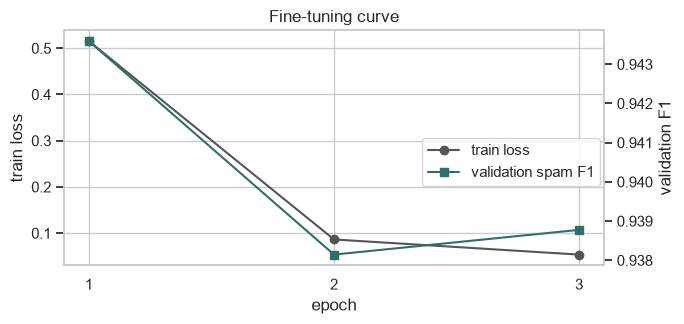

In [18]:
fig, ax1 = plt.subplots(figsize=(7, 3.4))
ax1.plot(history.epoch, history.train_loss, marker='o', color='#555', label='train loss')
ax1.set_xlabel('epoch')
ax1.set_ylabel('train loss')
ax1.set_xticks(history.epoch)
ax2 = ax1.twinx()
ax2.plot(history.epoch, history.val_f1, marker='s', color='#2f6f6a', label='validation spam F1')
ax2.set_ylabel('validation F1')
ax2.grid(False)
fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5))
ax1.set_title('Fine-tuning curve')
plt.tight_layout()
plt.show()

## 6. Evaluation

### 6.1 Choosing the threshold on validation

0.5 is an arbitrary default. Section 1 argued that false positives cost more, so a precision-first rule ("the lowest threshold with spam precision of at least X") is tempting. We compare candidate rules **on validation only**; the test set stays untouched by this decision.

In [19]:
p_val_ft = predict_proba(model, val_df.text.tolist())
prec, rec, thr = precision_recall_curve(val_df.y, p_val_ft)

def lowest_threshold_with_precision(target):
    ok = np.where(prec[:-1] >= target)[0]
    return float(thr[ok[0]]) if len(ok) else None

grid = np.unique(np.concatenate([p_val_ft, [0.5]]))
f1s = [f1_score(val_df.y, p_val_ft >= t) for t in grid]
candidates = {'default 0.5': 0.5, 'max F1': float(grid[int(np.argmax(f1s))]),
              'precision >= 0.95': lowest_threshold_with_precision(0.95),
              'precision >= 0.97': lowest_threshold_with_precision(0.97)}
pd.DataFrame({name: {'threshold': t, 'precision': precision_score(val_df.y, p_val_ft >= t),
                     'recall': recall_score(val_df.y, p_val_ft >= t), 'f1': f1_score(val_df.y, p_val_ft >= t)}
              for name, t in candidates.items() if t is not None}).T.round(4)

,threshold,precision,recall,f1
default 0.5,0.5000,0.9388,0.9485,0.9436
max F1,0.4794,0.9394,0.9588,0.9490
precision >= 0.95,0.9795,0.9570,0.9175,0.9368
precision >= 0.97,0.9958,0.9773,0.8866,0.9297


In [20]:
THRESHOLD = round(candidates['max F1'], 4)
print(f'chosen threshold: {THRESHOLD}')

chosen threshold: 0.4794


**Decision: maximize F1 on validation.** The fine-tuned model's probabilities are very peaked: almost every message is scored near 0 or near 1. With only 97 spam messages in validation, demanding 97% precision pushes the threshold to the extreme tail (above 0.99), where each extra point of precision is bought with a large and noisy loss of recall. Max-F1 balances the two errors on the evidence we have and stays in the stable middle of the curve. The precision-first rules remain in the table so the trade-off is visible.

### 6.2 Final comparison on the test set

Every model is now scored once on the held-out test set. The baseline and zero-shot model use 0.5; the fine-tuned model uses the threshold chosen above.

In [21]:
p_test_ft = predict_proba(model, test_df.text.tolist())
y_test = test_df.y.values

def scores(p, t):
    pred = p >= t
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'threshold': t, 'accuracy': (tp + tn) / len(y_test), 'precision': precision_score(y_test, pred, zero_division=0),
            'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred), 'roc_auc': roc_auc_score(y_test, p),
            'avg_precision': average_precision_score(y_test, p), 'false_positives': int(fp), 'false_negatives': int(fn)}

results = pd.DataFrame({
    'TF-IDF + LogReg baseline': scores(p_test_base, 0.5),
    'Pretrained, zero-shot': scores(p_test_zero, 0.5),
    'Pretrained, fine-tuned on SMS': scores(p_test_ft, THRESHOLD),
}).T
results.style.format(precision=3).highlight_max(subset=['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'avg_precision'], color='#cfe8e4')

,threshold,accuracy,precision,recall,f1,roc_auc,avg_precision,false_positives,false_negatives
TF-IDF + LogReg baseline,0.500,0.992,0.989,0.948,0.968,0.998,0.992,1.000,5.000
"Pretrained, zero-shot",0.500,0.421,0.136,0.688,0.228,0.617,0.177,418.000,30.000
"Pretrained, fine-tuned on SMS",0.479,0.991,0.968,0.958,0.963,0.999,0.994,3.000,4.000


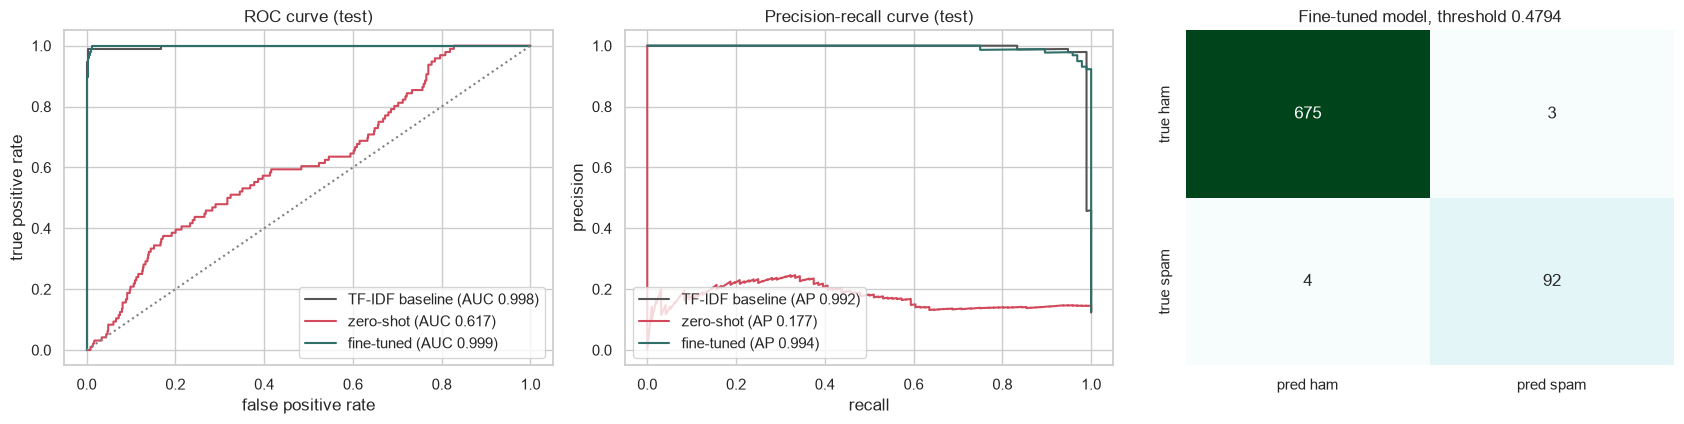

              precision    recall  f1-score   support

         ham      0.994     0.996     0.995       678
        spam      0.968     0.958     0.963        96

    accuracy                          0.991       774
   macro avg      0.981     0.977     0.979       774
weighted avg      0.991     0.991     0.991       774



In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
curves = [('TF-IDF baseline', p_test_base, '#555'), ('zero-shot', p_test_zero, '#d1495b'), ('fine-tuned', p_test_ft, '#2f6f6a')]
for name, p, c in curves:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, label=f'{name} (AUC {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=c, label=f'{name} (AP {average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], ls=':', color='grey')
axes[0].set(title='ROC curve (test)', xlabel='false positive rate', ylabel='true positive rate')
axes[1].set(title='Precision-recall curve (test)', xlabel='recall', ylabel='precision')
axes[0].legend(loc='lower right')
axes[1].legend(loc='lower left')

cm = confusion_matrix(y_test, p_test_ft >= THRESHOLD)
sns.heatmap(cm, annot=True, fmt='d', cmap='BuGn', cbar=False, ax=axes[2],
            xticklabels=['pred ham', 'pred spam'], yticklabels=['true ham', 'true spam'])
axes[2].set_title(f'Fine-tuned model, threshold {THRESHOLD}')
plt.tight_layout()
plt.show()
print(classification_report(y_test, p_test_ft >= THRESHOLD, target_names=['ham', 'spam'], digits=3))

### 6.3 Error analysis

Numbers hide the failure modes. We read the messages the fine-tuned model gets wrong on test.

In [23]:
errors = test_df.assign(p_spam=p_test_ft, pred=(p_test_ft >= THRESHOLD).astype(int))
errors = errors[errors.pred != errors.y]
pd.set_option('display.max_colwidth', 160)
print('False positives (ham flagged as spam):')
display(errors[errors.y == 0].sort_values('p_spam', ascending=False)[['p_spam', 'text']].head(8).round(3))
print('False negatives (spam that slipped through):')
display(errors[errors.y == 1].sort_values('p_spam')[['p_spam', 'text']].head(8).round(3))

False positives (ham flagged as spam):


,p_spam,text
4410,0.997,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to <#>
1456,0.992,Total video converter free download type this in google search:)
3655,0.641,Unlimited texts. Limited minutes.


False negatives (spam that slipped through):


,p_spam,text
3327,0.064,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!"
2721,0.081,Adult 18 Content Your video will be with you shortly
2326,0.109,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1
3173,0.477,Sorry I missed your call let's talk when you have the time. I'm on 07090201529


**Patterns.** The remaining false negatives are mostly spam that imitates a personal tone (no prize, no short code, conversational phrasing) or very short teasers. The few false positives are ham that borrows spam vocabulary: forwarded promotions, messages with prices or phone numbers. These are the same cues section 2 identified, which says the model learned the right signals and now fails only where those signals genuinely conflict.

### 6.4 Does the multilingual knowledge survive?

The base model is multilingual and our fine-tuning data is English only. A quick sanity check with Spanish and French messages and with email subjects in the style of the model card shows what adapting to SMS kept and what it erased. The TF-IDF baseline is included as a reference: it only knows the English vocabulary it was trained on.

In [24]:
probe = [
    ('Felicidades! Ganaste un iPhone 17. Reclámalo ahora enviando GANAR al 55555', 1),
    ('Tu cuenta bancaria fue bloqueada. Verifica tus datos en este enlace hoy mismo', 1),
    ('Hola mamá, llego tarde a la cena, guárdame algo porfa', 0),
    ('¿Nos vemos mañana a las 3 en la biblioteca para el proyecto?', 0),
    ('Félicitations ! Vous avez gagné un iPhone.', 1),
    ('Bonjour, la réunion est déplacée à 15h.', 0),
    ('Claim your free prize now!', 1),
    ('Meeting rescheduled to 3 PM', 0),
]
probe_df = pd.DataFrame(probe, columns=['text', 'expected'])
probe_df['baseline'] = baseline.predict_proba(tfidf(probe_df.text))[:, 1].round(3)
probe_df['zero-shot'] = predict_proba(pretrained, probe_df.text.tolist()).round(3)
probe_df['fine-tuned'] = predict_proba(model, probe_df.text.tolist()).round(3)
probe_df['fine-tuned correct'] = (probe_df['fine-tuned'] >= THRESHOLD).astype(int) == probe_df.expected
probe_df

,text,expected,baseline,zero-shot,fine-tuned,fine-tuned correct
0,Felicidades! Ganaste un iPhone 17. Reclámalo ahora enviando GANAR al 55555,1,0.084,0.999,0.991,True
1,Tu cuenta bancaria fue bloqueada. Verifica tus datos en este enlace hoy mismo,1,0.038,0.999,0.950,True
2,"Hola mamá, llego tarde a la cena, guárdame algo porfa",0,0.057,0.001,0.004,True
3,¿Nos vemos mañana a las 3 en la biblioteca para el proyecto?,0,0.036,0.001,0.004,True
4,Félicitations ! Vous avez gagné un iPhone.,1,0.149,0.999,0.043,False
5,"Bonjour, la réunion est déplacée à 15h.",0,0.040,0.001,0.004,True
6,Claim your free prize now!,1,0.998,0.999,0.997,True
7,Meeting rescheduled to 3 PM,0,0.076,0.001,0.003,True


**Reading the probe.** These are a handful of hand-written messages, so this is an illustration, not a measurement. The `fine-tuned correct` column shows which non-English messages survive English-only fine-tuning at the chosen threshold. Whatever was lost is a known limitation, and the website states it instead of hiding it.

### 6.5 Which model do we ship?

On this English test set the fine-tuned transformer and the TF-IDF baseline are practically tied on F1 (a message or two apart out of 774), while the transformer ranks messages better (ROC-AUC and average precision). We ship the fine-tuned transformer because the project asks us to integrate the pretrained model, because its better ranking makes the threshold choice more stable, and because its multilingual tokenizer degrades more gracefully outside the training vocabulary. We are explicit that a well-tuned linear model is a very strong baseline on this dataset.

## 7. Deployment artifacts

The web app needs two things:

1. **The fine-tuned weights**, saved in half precision (fp16) to halve the download size; the app casts them back to fp32 on CPU. The folder is too large for a normal git commit, so the README explains how to obtain it, and the app falls back to the original Hugging Face model if it is missing.
2. **A model card** (`app/classifier/model_card.json`) with the threshold and the real test metrics from this notebook, so every number the website shows is traceable to this run.

In [25]:
FINETUNED_DIR.mkdir(parents=True, exist_ok=True)
model.half().save_pretrained(FINETUNED_DIR)
tokenizer.save_pretrained(FINETUNED_DIR)
model.float()
size_mb = sum(f.stat().st_size for f in FINETUNED_DIR.iterdir()) / 1e6
print(f'saved to {FINETUNED_DIR} ({size_mb:.0f} MB)')

def as_dict(row):
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in row.items()}

card = {
    'base_model': PRETRAINED,
    'architecture': pretrained.config.architectures[0],
    'parameters_millions': round(n_params / 1e6),
    'max_length': MAX_LEN,
    'threshold': THRESHOLD,
    'dataset': {'name': 'SMS Spam Collection (UCI)', 'raw_messages': int(len(df)), 'unique_messages': int(len(clean)),
                'spam_share': round(float(clean.y.mean()), 4),
                'split': {k: int(len(v)) for k, v in splits.items()}},
    'training': {'epochs': EPOCHS, 'batch_size': BATCH, 'learning_rate': LR, 'frozen': 'word embeddings',
                 'best_epoch': int(history.loc[history.val_f1.idxmax(), 'epoch'])},
    'test_metrics': {
        'baseline_tfidf_logreg': as_dict(results.loc['TF-IDF + LogReg baseline']),
        'pretrained_zero_shot': as_dict(results.loc['Pretrained, zero-shot']),
        'pretrained_fine_tuned': as_dict(results.loc['Pretrained, fine-tuned on SMS']),
    },
}
MODEL_CARD.parent.mkdir(parents=True, exist_ok=True)
MODEL_CARD.write_text(json.dumps(card, indent=2), encoding='utf-8')
print(json.dumps(card['test_metrics']['pretrained_fine_tuned'], indent=2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to C:\Users\Juan Jose\Desktop\Maestria\semestre 3\Hacking AI\spam detection\model\finetuned (252 MB)
{
  "threshold": 0.4794,
  "accuracy": 0.991,
  "precision": 0.9684,
  "recall": 0.9583,
  "f1": 0.9634,
  "roc_auc": 0.9992,
  "avg_precision": 0.9944,
  "false_positives": 3.0,
  "false_negatives": 4.0
}


## 8. Conclusions

1. **EDA**: SMS spam is long (close to the 160-character limit), digit-heavy, and built on a small sales vocabulary (*free, call, claim, prize, txt*). Ham is short, informal and abbreviated.
2. **Privacy**: aggregate EDA can be released under ε-differential privacy with the Laplace mechanism at almost no cost in readability for ε ≈ 1, because our counts are large. The app applies data minimization: it never stores what users paste.
3. **The pretrained model does not transfer zero-shot** from email subjects to SMS. It flags most legitimate SMS as spam, and no threshold fixes it. This is a textbook domain shift.
4. **Fine-tuning the same model** on 70% of the SMS data lifts its spam F1 from about 0.23 to about 0.96 on the held-out test set. It matches a strong TF-IDF baseline on F1 and beats it on ROC-AUC and average precision, with the decision threshold chosen on validation. The honest takeaway: for English SMS a linear model is already excellent; the transformer earns its place through ranking quality and multilingual coverage, not raw F1.
5. **Limits**: English-only fine-tuning erodes part of the original multilingual ability (section 6.4). The corpus is from 2011-2012 and UK-centric. Modern smishing (fake parcel and bank alerts with links) is under-represented, so production use would need fresh data, periodic re-evaluation, and DP-SGD if user messages were ever used for training.

The results feed the web app: see `../app` and the project README for how to run it.